# CYP2D6 inhibitor classification: k-NN, random forest and SVM

The training and test sets come from `ShuffleandSplit` and are the same splits used for the MOE Binary QSAR models. A compound with an Activity Score of 40 or above is an inhibitor (1); everything below 40, including inconclusive compounds, is a non-inhibitor (0).

In [1]:
%matplotlib inline
from cyp_models import (
    CLASSIFIERS, evaluate, load_split, plot_calibration, rf_calibration, roc_test,
)

In [2]:
X_train, y_train, X_test, y_test = load_split("2d6")
print(f"Training: {len(y_train)} compounds, {y_train.sum()} inhibitors, "
      f"{len(y_train) - y_train.sum()} non-inhibitors")
print(f"Test:     {len(y_test)} compounds, {y_test.sum()} inhibitors, "
      f"{len(y_test) - y_test.sum()} non-inhibitors")
print(f"Features: {X_train.shape[1]} MOE 2-D descriptors")

Training: 4433 compounds, 2219 inhibitors, 2214 non-inhibitors
Test:     1109 compounds, 552 inhibitors, 557 non-inhibitors
Features: 186 MOE 2-D descriptors


## Classifiers

Hyperparameters are fixed in `cyp_models.py`, because scikit-learn's defaults for SVC `gamma` and random forest `n_estimators` have changed across releases.

In [3]:
CLASSIFIERS

{'k-NN': KNeighborsClassifier(),
 'Random Forest': RandomForestClassifier(n_estimators=10, random_state=0),
 'SVM': SVC(gamma='auto')}

## Validation

- **Training set:** 5-fold cross-validation.
- **Test set:** each model is fit on the full training set and then predicts the held-out test set. The scaler is part of the pipeline, so it too is fit on training data only.

In [4]:
results, test_confusion = evaluate(X_train, y_train, X_test, y_test)
results

,Method,Set,Accuracy,TPR,TNR
0,k-NN,Training (5-fold CV),0.717,0.753,0.681
1,k-NN,Test,0.718,0.746,0.689
2,Random Forest,Training (5-fold CV),0.728,0.649,0.806
3,Random Forest,Test,0.729,0.649,0.808
4,SVM,Training (5-fold CV),0.759,0.756,0.762
5,SVM,Test,0.752,0.726,0.777


## Test set confusion matrices

Rows are actual classes and columns are predicted classes, in the order non-inhibitor, inhibitor.

In [5]:
for name, cm in test_confusion.items():
    print(name)
    print(cm, end='\n\n')

k-NN
[[384 173]
 [140 412]]

Random Forest
[[450 107]
 [194 358]]

SVM
[[433 124]
 [151 401]]



## Random forest calibration

Each point is a bin of predicted probability (rounded to the nearest 0.1, since the forest has 10 trees). Its height is the fraction of compounds given that probability that are actually inhibitors, and its area is proportional to the number of such compounds. Points on the diagonal are perfectly calibrated.

,pred_prob,count,observed_freq
0,0.0,66,0.136364
1,0.1,98,0.173469
2,0.2,132,0.227273
3,0.3,103,0.330097
4,0.4,134,0.402985
5,0.5,111,0.450450
6,0.6,107,0.588785
7,0.7,86,0.697674
8,0.8,88,0.784091
9,0.9,81,0.876543


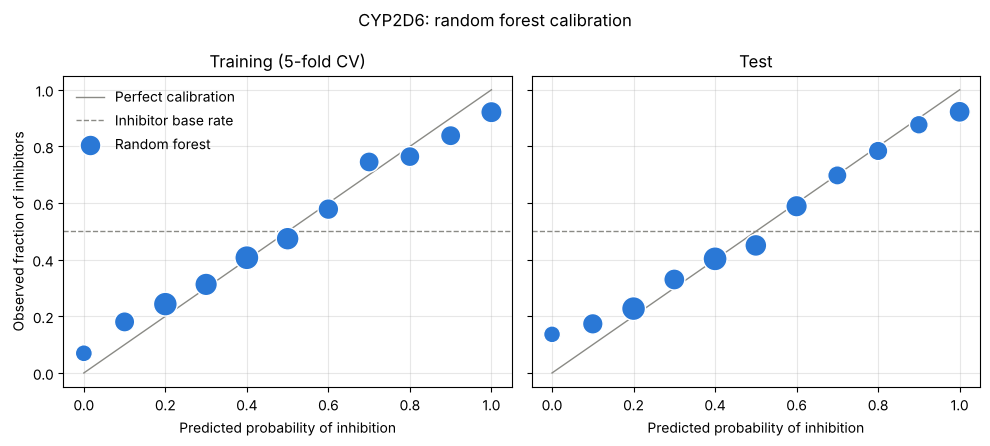

In [6]:
calibration = rf_calibration(X_train, y_train, X_test, y_test)
fig = plot_calibration(calibration, baseline=y_train.mean(), title="CYP2D6: random forest calibration")
fig.savefig("results/2d6_rf_calibration.png", dpi=150)
calibration["Test"]

## ROC curves on the test set

Each model is fit on the training set. Random forest and k-NN are scored by predicted probability, the SVM by its decision function.

,Method,Test AUC
0,k-NN,0.780
1,Random Forest,0.795
2,SVM,0.830


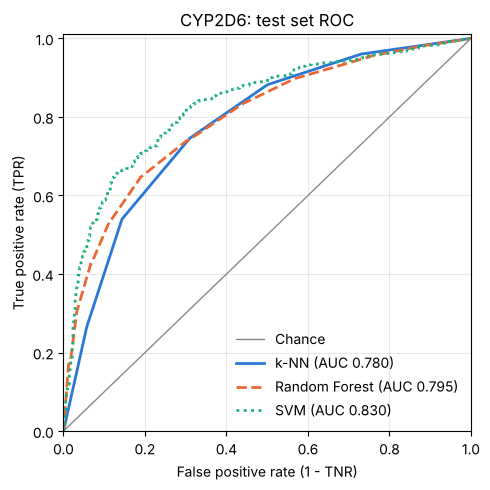

In [7]:
auc, fig = roc_test(X_train, y_train, X_test, y_test, title="CYP2D6: test set ROC")
fig.savefig("results/2d6_roc.png", dpi=150)
auc

In [8]:
results.merge(auc.assign(Set="Test"), how="left").to_csv("results/2d6.csv", index=False)